# Timing-driven placement in fifteen lines

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RayChang987/Attar/blob/main/examples/colab/timing_driven_colab.ipynb)

The README demo of [Attar](https://github.com/RayChang987/Attar), cell by cell: place an ASAP7 design (cva6, 121k
cells, 8 SRAMs) for wirelength, time it, weight the nets by their slack the way OpenROAD's timing-driven global
placement does, place again, time it again.

**Runtime -> Change runtime type -> T4 GPU** (it also runs on the CPU, only slower). On an RTX 4090 the whole
notebook runs in about 30 s once the kernels are compiled (section 2); a T4 takes a few times longer (an estimate,
not measured).

## 0. Setup

In [1]:
!pip install -q attar==1.0.8

In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
import attar

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('attar', attar.__version__, 'on', torch.cuda.get_device_name() if dev == 'cuda' else 'CPU')


def show(png):                            # a plot d.plot() wrote, inline
    plt.close('all')
    return Image(png)

def table(header, rows):
    """A results table, rendered as Markdown."""
    md = ['| ' + ' | '.join(header) + ' |', '|' + '---|' * len(header)]
    md += ['| ' + ' | '.join(str(v) for v in r) + ' |' for r in rows]
    display(Markdown('\n'.join(md)))


attar 1.0.8 on NVIDIA GeForce RTX 4090


## 1. Load and place for wirelength

`attar.load` fetches the design from the [Attar zoo](https://huggingface.co/datasets/RayChang987/attar-zoo) on
Hugging Face (a few MB, with its ASAP7 timing library) and puts it on the GPU as tensors. `d.place()` is global
placement plus legalization.

  place: GP 480 it (0.99s), LG (0.98s), HPWL 4.817e+05 (GP 4.52e+05), legal True, 1.99s


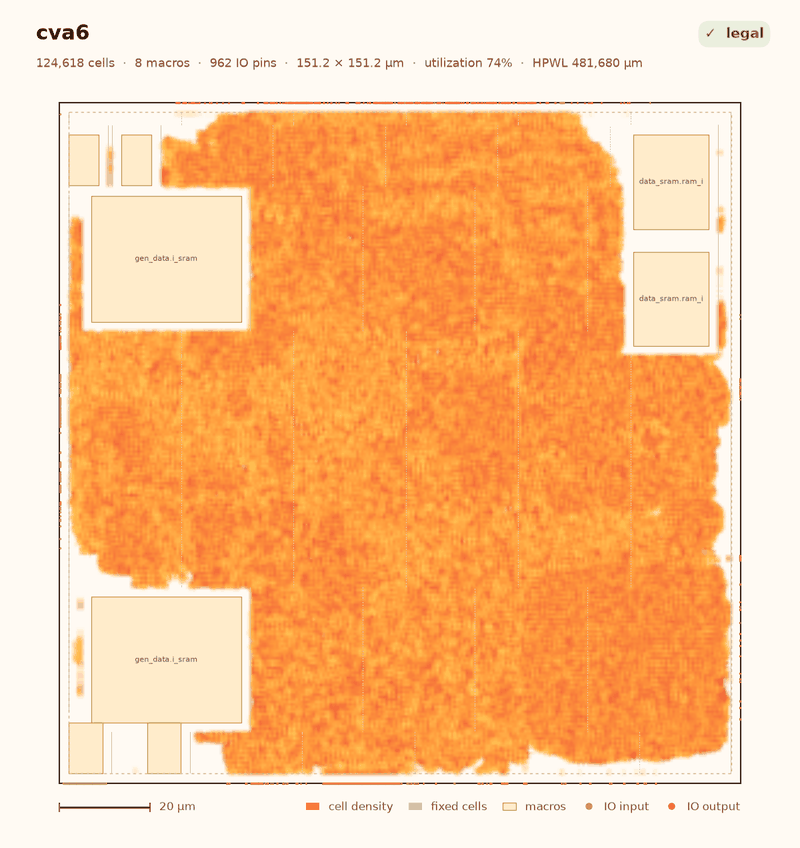

In [3]:
d = attar.load('after_fp/orfs_asap7/cva6', device=dev)
d.place()                                 # wirelength only
hpwl0 = float(d.hpwl())
d.plot('wirelength.png')
show('wirelength.png')

## 2. Time it

Static timing as OpenSTA computes it, with placement parasitics as OpenROAD estimates them.

The **first timing run in a fresh runtime compiles the GPU timer's Triton kernels: about two minutes**. Every
later run takes about a second.

In [4]:
before = d.timing_report(endpoints=0, path=False)
r0 = d.timing()
slack0 = r0.setup[r0.endpoints].cpu()            # every endpoint's setup slack (ps)

attar.timing: first GPU timing run on this machine: compiling its Triton kernels (a couple of minutes, once; cached in /root/.triton/cache; a fresh machine such as a new Colab runtime compiles again unless TRITON_CACHE_DIR and TORCHINDUCTOR_CACHE_DIR point to a folder it keeps)


Timing of cva6 (main_clk clocks, parasitics: placement estimate)
  setup: WNS -184.37 ps, TNS -88268.63 ps, 1384 of 9032 endpoints violated (worst slack -184.37 ps)
  hold:  WHS 0.00 ps, THS 0.00 ps, 0 violated


## 3. Weight the nets by their slack

`net_slack()` gives every net's setup slack, as OpenSTA's `Sta::netSlack` (infinite for unconstrained nets).

In [5]:
s = d.timing().net_slack()                # every net, as OpenSTA
print('%d nets with a slack, %d of them negative; worst %.1f ps' % (s.isfinite().sum(), (s < 0).sum(), float(s.min())))

114282 nets with a slack, 14050 of them negative; worst -184.4 ps


OpenROAD's `gpl` weights the worst 10 % of the nets, ramping their weight from 1 to 5 by criticality. The weights
are a tensor, `d.n_weight`; the next placement reads them. This is the part to change for your own method: any
weighting, any formula.

In [6]:
v = s[s.isfinite()].sort().values
v = v[:len(v) // 10]                      # the worst 10 %
lo, hi = v[len(v) // 50], v[-1]           # the ramp: weight 5 at lo and below, 1 at hi
w = d.n_weight
d.n_weight = w * (1 + 4 * ((hi - s) / (hi - lo)).clamp(0, 1))
print('%d nets weighted, from %.1f ps (weight 5) to %.1f ps (weight 1)' % (len(v), float(lo), float(hi)))

11428 nets weighted, from -172.8 ps (weight 5) to -29.7 ps (weight 1)


## 4. Place again, timing-driven, and time it

Timing of cva6 (main_clk clocks, parasitics: placement estimate)
  setup: WNS -77.34 ps, TNS -5406.30 ps, 344 of 9032 endpoints violated (worst slack -77.34 ps)
  hold:  WHS -2.17 ps, THS -8.22 ps, 10 violated


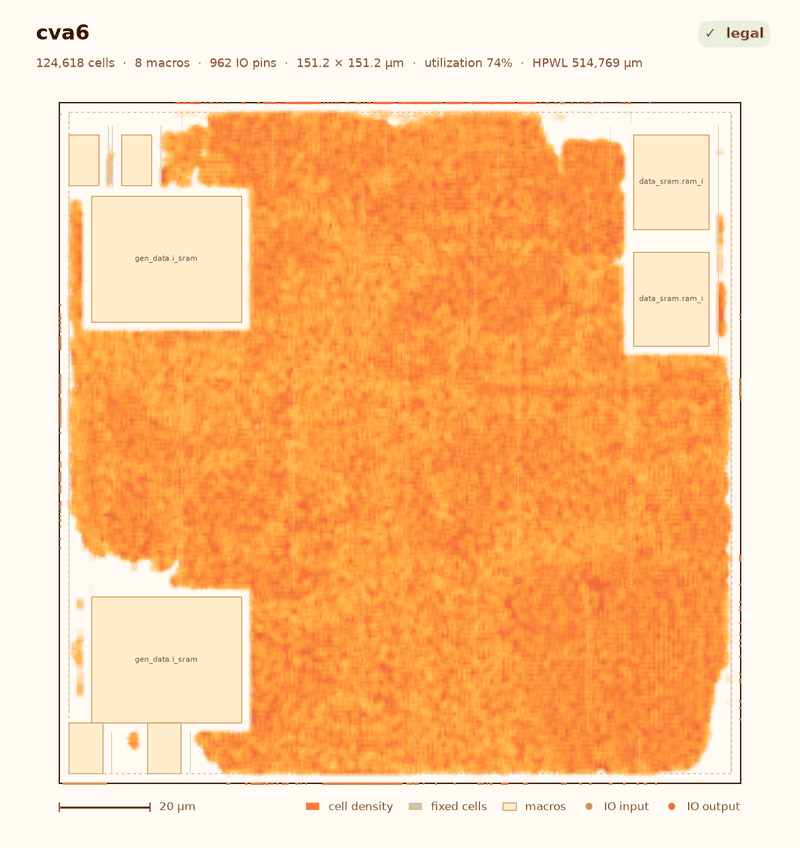

In [7]:
d.place(verbose=False)                    # timing-driven
d.n_weight = w                            # back to the netlist's weights (HPWL, plots)
after = d.timing_report(endpoints=0, path=False)
r1 = d.timing()
slack1 = r1.setup[r1.endpoints].cpu()
d.plot('timing_driven.png')
show('timing_driven.png')

## 5. Results

The same netlist and placer; only the net weights differ.

|  | wirelength-driven | timing-driven | change |
|---|---|---|---|
| WNS (ps) | -184.4 | -77.3 | +107.0 ps |
| TNS (ps) | -88269 | -5406 | 0.06x |
| setup violations | 1384 | 344 | -1040 |
| HPWL (um) | 481680 | 514769 | +6.9% |
| legal |  | True |  |

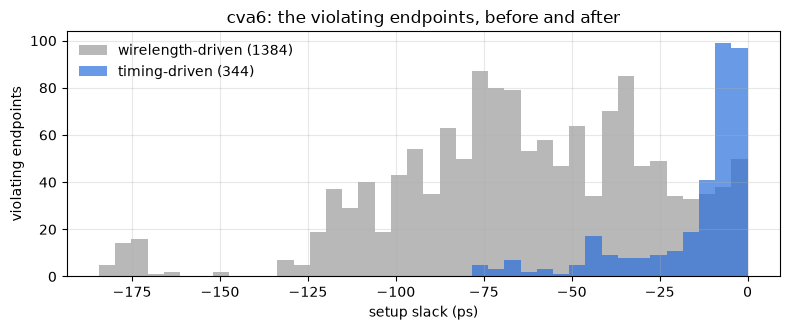

In [8]:
hpwl1 = float(d.hpwl())
table(['', 'wirelength-driven', 'timing-driven', 'change'],
      [['WNS (ps)', '%.1f' % before['wns'], '%.1f' % after['wns'], '%+.1f ps' % (after['wns'] - before['wns'])],
       ['TNS (ps)', '%.0f' % before['tns'], '%.0f' % after['tns'], '%.2fx' % (after['tns'] / before['tns'])],
       ['setup violations', before['setup_violations'], after['setup_violations'],
        '%+d' % (after['setup_violations'] - before['setup_violations'])],
       ['HPWL (um)', '%.0f' % hpwl0, '%.0f' % hpwl1, '%+.1f%%' % (100 * (hpwl1 / hpwl0 - 1))],
       ['legal', '', attar.Evaluator(d).legality()['legal'], '']])

v0, v1 = slack0[slack0.isfinite() & (slack0 < 0)], slack1[slack1.isfinite() & (slack1 < 0)]
bins = np.linspace(float(min(v0.min(), v1.min())), 0, 41)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(v0.numpy(), bins=bins, color='#9a9a9a', alpha=.7, label='wirelength-driven (%d)' % len(v0))
ax.hist(v1.numpy(), bins=bins, color='#2a6fdb', alpha=.7, label='timing-driven (%d)' % len(v1))
ax.set_xlabel('setup slack (ps)'); ax.set_ylabel('violating endpoints'); ax.grid(alpha=.3); ax.legend(frameon=False)
ax.set_title('cva6: the violating endpoints, before and after')
plt.tight_layout(); plt.show()

## 6. Take it out

`d.export` writes the placement into the design's own DEF (die, rows, PDN, macros kept), ready for OpenROAD to
route and sign off.

In [9]:
d.export('cva6_timing_driven.def');
# from google.colab import files; files.download('cva6_timing_driven.def')

## Next

* Another design: `attar.zoo('after_fp', remote=True)` lists them, e.g. `after_fp/orfs_asap7/swerv` (the second
  design in the README demo).
* Timing-driven placement research on Attar, step by step:
  [net and pin weighting on superblue18](https://colab.research.google.com/github/RayChang987/Attar/blob/main/examples/colab/p11_attar_superblue18.ipynb)
  and [LATTE, timing-driven detailed placement](https://colab.research.google.com/github/RayChang987/Attar/blob/main/examples/colab/latte_on_attar.ipynb).
* Your own weighting, or your own placer on `d.pos`: the [API](https://github.com/RayChang987/Attar/blob/main/docs/api.md)
  and the [examples](https://github.com/RayChang987/Attar/tree/main/examples).